https://www.kaggle.com/code/darshan1504/exploring-diffusion-models-with-jax

In [18]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Layer
import keras

from matplotlib import pyplot as plt
tf.random.set_seed(42)

In [19]:
IMAGE_SIZE = 64
BATCH_SIZE = 64
CHANNELS = 3
EPOCHS = 300
TIMESTEPS = 500
LEARNING_RATE = 1e-4
FILE_NAME = "dogs.weights.h5"
IS_TRAINING = False

print(IMAGE_SIZE, BATCH_SIZE, CHANNELS, EPOCHS, TIMESTEPS, LEARNING_RATE, FILE_NAME)

64 64 3 300 500 0.0001 dogs.weights.h5


Found 4739 files.


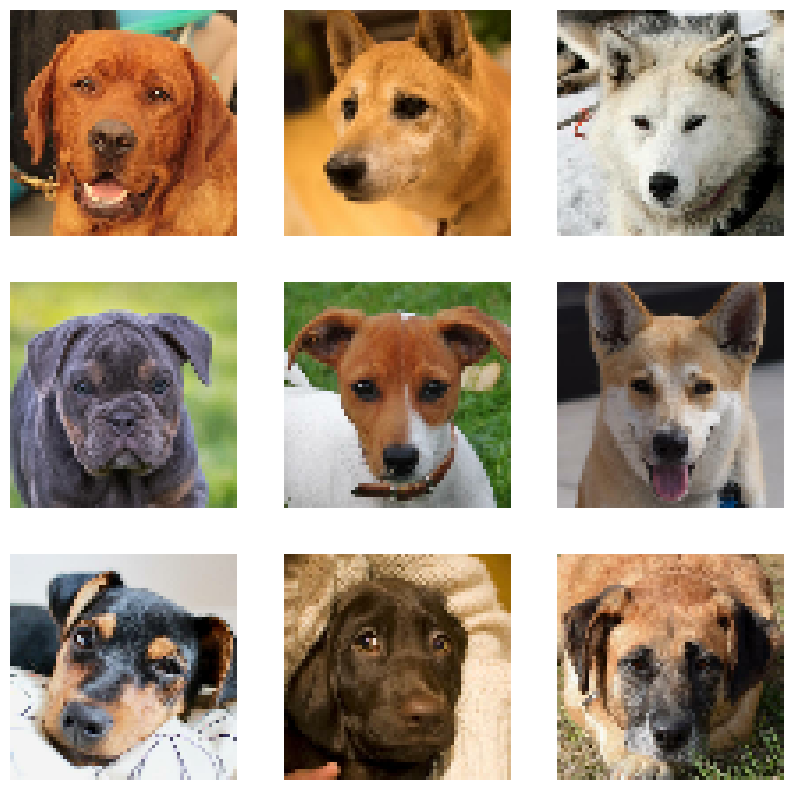

Dataset is ready for training!


2026-01-27 09:41:58.931872: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [20]:
DATASET_PATH = './afhq/train/dog'

def preprocess(images):
    # Convert to float
    images = tf.cast(images, tf.float32)
    # Map from [0, 255] to [-1, 1]
    images = (images / 127.5) - 1.0
    return images

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    labels=None,        # We only need images for basic diffusion
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMAGE_SIZE, IMAGE_SIZE), # Resizes automatically
    shuffle=True,
    seed=42,
    interpolation='bilinear'
)

# Apply the preprocessing
train_ds = train_ds.map(preprocess)
x_train = train_ds.cache().shuffle(buffer_size=500).prefetch(buffer_size=tf.data.AUTOTUNE)
TOTAL_STEPS = len(x_train) * EPOCHS

for batch in x_train.take(1):
    # We need to un-normalize ([-1, 1] -> [0, 1]) just for plotting
    images_to_plot = (batch + 1.0) / 2.0
    
    plt.figure(figsize=(10, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images_to_plot[i])
        plt.axis("off")
    plt.show()
    
print("Dataset is ready for training!")

$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \alpha_t} \epsilon$$

$$noisy \space image = \sqrt{\bar{\alpha}_t} \times image + \sqrt{1- \bar{\alpha}_t} \times noise$$

In [21]:
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=LEARNING_RATE,
    decay_steps=TOTAL_STEPS,
    alpha=0.1  # Minimum learning rate = 0.1 × initial
)
optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)
loss_fn = tf.keras.losses.MeanSquaredError()

# create a fixed linear beta schedule
beta_start = 0.0001
beta_end = 0.02
beta = tf.linspace(beta_start, beta_end, TIMESTEPS)

alpha = 1 - beta
alpha_bar = tf.math.cumprod(alpha, axis=0)
alpha_bar = tf.concat([tf.constant([1.0]), alpha_bar[:-1]], axis=0)
sqrt_alpha_bar = tf.math.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = tf.math.sqrt(1-alpha_bar)


# this function will add noise to the input as per the given timestamp
@tf.function
def forward_noise(x_0, t):
    noise = tf.random.normal(shape=tf.shape(x_0), dtype=tf.float32)
    batch_sqrt_alpha = tf.gather(sqrt_alpha_bar, t)
    batch_sqrt_one_minus_alpha_bar = tf.gather(sqrt_one_minus_alpha_bar, t)

    reshaped_sqrt_alpha = tf.reshape(batch_sqrt_alpha, (-1, 1, 1, 1))
    reshaped_sqrt_one_minus_alpha_bar = tf.reshape(batch_sqrt_one_minus_alpha_bar, (-1, 1, 1, 1))

    # Applying the actual formula
    noisy_image = (reshaped_sqrt_alpha * x_0) + (reshaped_sqrt_one_minus_alpha_bar * noise)
    return noisy_image, noise

# this function will be used to create sample timestamps between 0 &amp; T
@tf.function
def generate_timestamp(num):
    return tf.random.uniform(shape=[num], minval=0, maxval=TIMESTEPS, dtype=tf.int32)

In [ ]:
class SinusoidalPosEmb(Layer):
    def __init__(self, dim=64, max_positions=10000):
        super(SinusoidalPosEmb, self).__init__()
        self.dim = dim
        self.max_positions = max_positions

    def call(self, x, training=True):
        x = tf.cast(x, tf.float32)
        half_dim = self.dim // 2

        emb = tf.math.log(tf.cast(self.max_positions, tf.float32)) / (half_dim - 1)
        emb = tf.math.exp(tf.range(half_dim, dtype=tf.float32) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = tf.concat([tf.math.sin(emb), tf.math.cos(emb)], axis=-1)

        return emb

class TimeEmbedding(Layer):
    def __init__(self, dim=64, **kwargs):
        super(TimeEmbedding, self).__init__(**kwargs)
        self.dim = dim
        self.time_emb = 4*dim

        self.emb = SinusoidalPosEmb(dim)
        self.dense1 = layers.Dense(self.time_emb)
        self.act = layers.Activation("swish")
        self.dense2 = layers.Dense(self.time_emb)

    def call(self, x, training=True):
        x = self.emb(x)
        x = self.dense1(x)
        x = self.act(x)
        x = self.dense2(x)
        return x

class Attention(Layer):
    def __init__(self, dim, num_heads=8, **kwargs):
        super(Attention, self).__init__(**kwargs)
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads 
        
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=self.head_dim)

    def call(self, x):
        batch_size = tf.shape(x)[0]
        h, w = x.shape[1], x.shape[2]
        
        flat_x = tf.reshape(x, (batch_size, h*w, self.dim))
        attn_x = self.mha(flat_x, flat_x)
        
        out_x = tf.reshape(attn_x, (batch_size, h, w, self.dim))
        return out_x

class Block(Layer):
    def __init__(self, dim=64, **kwargs):
        super(Block, self).__init__(**kwargs)
        self.conv = layers.Conv2D(dim, (3,3), padding="same")
        self.norm = layers.GroupNormalization(groups=8)
        self.act = layers.Activation("swish")
    
    def call(self, x, training=True):
        x = self.conv(x)
        x = self.norm(x)
        x = self.act(x)
        return x

class ResNetBlock(layers.Layer):
    def __init__(self, out_channels=64, **kwargs):
        super(ResNetBlock, self).__init__(**kwargs)
        self.out_channels = out_channels
        
        # --- BLOCK 1 ---
        self.conv_block1 = Block(out_channels)

        # --- TIME PROCESSING ---
        # Takes the time vector and formats it to match the image channels
        self.time_dense = layers.Dense(out_channels)
        self.time_act = layers.Activation("swish")

        # --- BLOCK 2 ---
        self.conv_block2 = Block(out_channels)

        # --- RESIDUAL MATCHING ---
        # A 1x1 Conv to ensure input shape matches output shape for adding
        self.res_conv = layers.Conv2D(out_channels, 1, padding="same")

    def call(self, x, t_emb=None):
        # 1. Save input for later (Residual connection)
        input_x = x
        
        # 2. First Convolution Block
        h = self.conv_block1(input_x)

        # 3. Inject Time (CRITICAL STEP)
        if t_emb is not None:
            # Process time
            t = tf.squeeze(t_emb, axis=1)
            t = self.time_act(t)
            t = self.time_dense(t)
            # Reshape time to (Batch, 1, 1, Channels) so it broadcasts over the image
            t = tf.expand_dims(tf.expand_dims(t, 1), 1)
            # Add time to the image features
            h = h + t

        # 4. Second Convolution Block
        h = self.conv_block2(h)

        # 5. Residual Connection
        # We transform the original input to match the output channels
        residual = self.res_conv(input_x)
        
        # Return: Original(transformed) + New Learned Features
        return h + residual


In [23]:
def build_unet(img_size):
    dim = 32
    dim_scale_factor = (1, 2, 4, 8)
    ATTN_RESOLUTIONS = (16, 8)
    num_groups = 8
    channels = CHANNELS

    image_input = layers.Input(shape=(img_size, img_size, channels), name="image_input")
    time_input = layers.Input(shape=(1,), name="time_input")

    t_emb = TimeEmbedding(dim)(time_input)

    x = layers.Conv2D(dim, kernel_size=7, padding="same")(image_input)

    skips = [] # List to store the "sketches" for the skip connections
    dims = [dim * i for i in dim_scale_factor] # e.g., [32, 64, 128, 256]

    # ==========================================
    # 3. Downsampling Path (Left Side)
    # ==========================================
    for index, current_dim in enumerate(dims):
        current_res = img_size // (2 ** index)

        # --- A. ResNet Blocks with Time Injection ---
        x = ResNetBlock(current_dim)(x, t_emb)
        x = ResNetBlock(current_dim)(x, t_emb)

        if current_res in ATTN_RESOLUTIONS:
            attn = Attention(current_dim)(x)
            norm = layers.GroupNormalization(groups=num_groups)(attn)
            x = norm + x

        skips.append(x)

        if index != len(dims) - 1:
            x = layers.Conv2D(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # ==========================================
    # 4. Middle Block (Bottleneck)
    # ==========================================
    mid_dim = dims[-1]
    x = ResNetBlock(mid_dim)(x, t_emb)
    attn = Attention(mid_dim)(x)
    norm = layers.GroupNormalization(groups=num_groups)(attn)
    x = norm + x
    x = ResNetBlock(mid_dim)(x, t_emb)

    # ==========================================
    # 5. Upsampling Path (Right Side)
    # ==========================================
    for index, current_dim in enumerate(reversed(dims)):
        current_res = img_size // (2 ** (len(dims) - 1 - index))
        
        skip_layer = skips.pop() 
        x = layers.Concatenate()([skip_layer, x])

        x = ResNetBlock(current_dim)(x, t_emb)
        x = ResNetBlock(current_dim)(x, t_emb)

        if current_res in ATTN_RESOLUTIONS:
            attn = Attention(current_dim)(x)
            norm = layers.GroupNormalization(groups=num_groups)(attn)
            x = norm + x

        if index != len(dims) - 1:
            x = layers.Conv2DTranspose(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # ==========================================
    # 6. Final Output
    # ==========================================
    x = ResNetBlock(dim)(x, t_emb)
    output = layers.Conv2D(channels, kernel_size=1, padding="same")(x)

    # Create the Model
    return models.Model(inputs=[image_input, time_input], outputs=output, name="UNet")

# ==========================================
# How to use it
# ==========================================
model = build_unet(img_size=IMAGE_SIZE)
model.summary()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_62 (Conv2D)  │ (None, 64, 64,    │      4,736 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_embedding_1    │ (None, 1, 128)    │     20,736 │ time_input[0][0]  │
│ (TimeEmbedding)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_19    │ (None, 64, 64,    │     23,808 │ conv2d_62[0][0],  │
│ (ResNetBlock)       │ 32)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_20    │ (None, 64, 64,    │     23,808 │ res_net_block_19… │
│ (ResNetBlock)       │ 32)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_69 (Conv2D)  │ (None, 32, 32,    │     16,416 │ res_net_block_20… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_21    │ (None, 32, 32,    │     66,048 │ conv2d_69[0][0],  │
│ (ResNetBlock)       │ 64)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_22    │ (None, 32, 32,    │     86,528 │ res_net_block_21… │
│ (ResNetBlock)       │ 64)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_76 (Conv2D)  │ (None, 16, 16,    │     65,600 │ res_net_block_22… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_23    │ (None, 16, 16,    │    246,784 │ conv2d_76[0][0],  │
│ (ResNetBlock)       │ 128)              │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_24    │ (None, 16, 16,    │    328,704 │ res_net_block_23… │
│ (ResNetBlock)       │ 128)              │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_5         │ (None, 16, 16,    │     66,048 │ res_net_block_24… │
│ (Attention)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        256 │ attention_5[0][0] │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 16, 16,    │          0 │ group_normalizat… │
│                     │ 128)              │            │ res_net_block_24… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_83 (Conv2D)  │ (None, 8, 8, 128) │    262,272 │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_25    │ (None, 8, 8, 256) │    952,320 │ conv2d_83[0][0],  │
│ (ResNetBlock)       │                   │            │ time_embedding_1

 Total params: 12,785,539 (48.77 MB)

 Trainable params: 12,785,539 (48.77 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
@tf.function
def train_step(images):
    batch_size = tf.shape(images)[0]
    images = tf.cast(images, tf.float32)

    # Generate random timesteps for each image in the batch
    t = generate_timestamp(batch_size)
    noisy_images, noise = forward_noise(images, t)

    # Convert timestep to float 
    t_float = tf.cast(t, dtype=tf.float32)
    t_float = tf.reshape(t_float, (-1, 1))

    with tf.GradientTape() as tape:
        predicted_noise = model([noisy_images, t_float], training=True)
        loss = loss_fn(noise, predicted_noise)

    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

In [25]:
import time

def train_model():
    # Params for early stopping
    best_loss = float('inf')
    patience = 15
    wait = 0

    print("Starting Training...")

    for epoch in range(EPOCHS):
        start_time = time.time()
        epoch_loss = 0
        steps = 0
        batch_count = 0
        for batch_images in x_train:
            loss = train_step(batch_images)
            epoch_loss += loss
            steps += 1
            batch_count += 1
            if batch_count % 10 == 0:
                print(f"Batch {batch_count} - Loss: {loss:.4f}")

        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {epoch_loss/steps:.4f}, time taken: {time.time()-start_time}")

        avg_loss = epoch_loss / steps
        if avg_loss < best_loss:
            best_loss = avg_loss
            wait = 0
            # Save the best model
            model.save_weights(str(steps)+FILE_NAME)
            print(f"  > Loss improved. Saving model.")
        else:
            wait += 1
            print(f"  > No improvement. Patience: {wait}/{patience}")
            if wait >= patience:
                print("  > Early Stopping triggered!")
                # Load back the best weights
                model.load_weights(str(steps)+FILE_NAME)
                break

In [36]:
print(FILE_NAME)

if IS_TRAINING:
    train_model()
    model.save_weights(FILE_NAME)
    model.save("dogs-500-timesteps.keras")
    print("Model weights saved to", FILE_NAME)
else:
    model.load_weights(FILE_NAME)
    print("Model weights loaded from", FILE_NAME)

dogs.weights.h5
Model weights loaded from dogs.weights.h5


In [40]:
import random
from tqdm import tqdm

def backward_denoising_ddpm(x_t, pred_noise, t):
    alpha_t = tf.gather(alpha, t)
    alpha_t_bar = tf.gather(alpha_bar, t)

    eps_coef = (1 - alpha_t) / (1 - alpha_t_bar) ** .5  
    mean = 1 / (alpha_t ** 0.5) * (x_t - eps_coef * pred_noise)
    
    var = tf.gather(beta, t)
    z = tf.random.normal(tf.shape(x_t), dtype=tf.float32)

    return mean + (var ** 0.5) * z

def backward_denoising_ddim(x_t, pred_noise, t, sigma_t):
  alpha_bar_t = tf.gather(alpha_bar, t)
  alpha_t_minus_one = tf.gather(alpha, t - 1)
    
  # predicted x_0
  pred = (x_t - ((1 - alpha_bar_t) ** 0.5) * pred_noise)/ (alpha_bar_t ** 0.5)
  pred = (alpha_t_minus_one ** 0.5) * pred
    
  # direction pointing to x_t
  pred = pred + ((1 - alpha_t_minus_one - (sigma_t ** 2)) ** 0.5) * pred_noise
  
  # random noise
  eps_t = tf.random.normal(tf.shape(x_t), dtype=tf.float32)
  pred = pred + (sigma_t * eps_t)
  
  return pred

  0%|          | 0/499 [00:00<?, ?it/s]

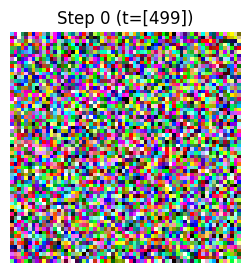

 10%|█         | 50/499 [00:09<01:22,  5.45it/s]

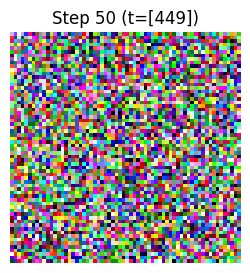

 20%|██        | 100/499 [00:18<01:08,  5.85it/s]

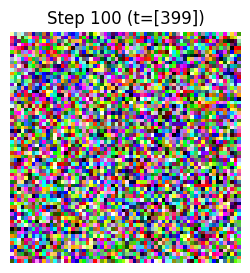

 30%|███       | 150/499 [00:27<00:57,  6.02it/s]

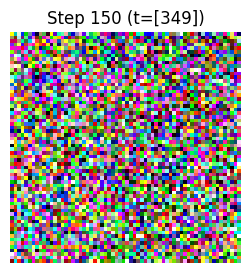

 40%|████      | 200/499 [00:35<00:49,  6.01it/s]

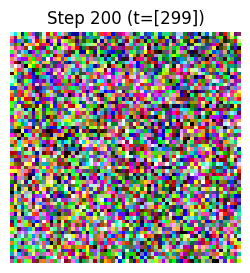

 50%|█████     | 250/499 [00:43<00:41,  5.98it/s]

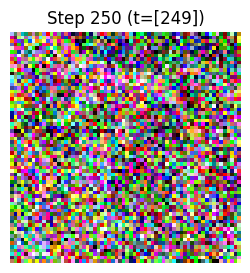

 60%|██████    | 300/499 [00:52<00:33,  5.99it/s]

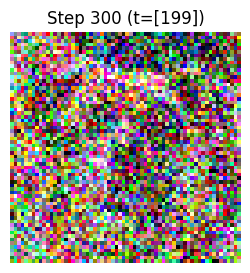

 70%|███████   | 350/499 [01:00<00:24,  6.01it/s]

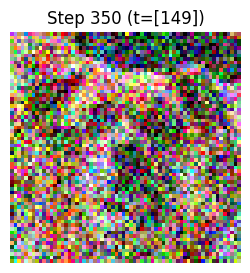

 80%|████████  | 400/499 [01:09<00:18,  5.25it/s]

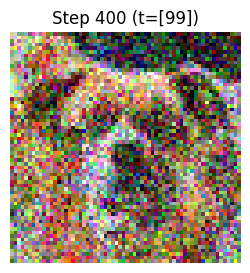

 90%|█████████ | 450/499 [01:18<00:07,  6.22it/s]

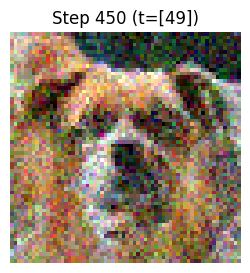

100%|██████████| 499/499 [01:26<00:00,  5.77it/s]


In [41]:
# Generating Gaussian noise
x = tf.random.normal((1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), dtype=tf.float32, seed=random.randint(0, 1000))


# Iterate over T timesteps
for i in tqdm(range(0, TIMESTEPS - 1)):
  # t-th timestep  
  t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
  
  # Predict noise using U-Net
  pred_noise = model([x, t])
  
  # Obtain the output from the noise using the formula seen before
  x = backward_denoising_ddpm(x, pred_noise, t)

  # Log the image after every 25 iterations
  if i % 50 == 0 or i == TIMESTEPS - 1:
    img_to_plot = x[0] 
        
    # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
    img_to_plot = (img_to_plot + 1.0) / 2.0
    
    # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
    img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

    plt.figure(figsize=(3,3))
    plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
    plt.title(f"Step {i} (t={t})")
    plt.axis('off')
    plt.show()


In [42]:
# # Create a list to store output images
# img_list_ddim = []

# # Generate some noise
# x = tf.random.normal((1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), dtype=tf.float32, seed=random.randint(0, 1000))

# # Define number of inference loops to run
# inference_timesteps = 100

# # Create a range of inference steps that the output should be sampled at
# inference_range = range(0, TIMESTEPS, TIMESTEPS // inference_timesteps)

# # Iterate over inference_timesteps
# for index, i in tqdm(enumerate(reversed(range(inference_timesteps))), total=inference_timesteps):
  
#   # Fetch t for that specific timestep  
#   t = tf.expand_dims(inference_range[i], 0) 
#   print(t)
  
#   # Predict the noise  
#   pred_noise = model([x, t])
   
#   # Obtain the output from the noise using the formula seen before
#   x = backward_denoising_ddim(x, pred_noise, t, 0)

#   # Log and display output image at every timestep
#   if index % 1 == 0:
#     img_to_plot = x[0] 
        
#     # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
#     img_to_plot = (img_to_plot + 1.0) / 2.0
    
#     # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
#     img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

#     plt.figure(figsize=(3,3))
#     plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
#     plt.title(f"Step {index} (t={t})")
#     plt.axis('off')
#     plt.show()

# # Display the final generated image
# img_to_plot = x[0] 
        
# # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
# img_to_plot = (img_to_plot + 1.0) / 2.0

# # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
# img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

# plt.figure(figsize=(3,3))
# plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
# plt.title(f"Step {i} (t={t})")
# plt.axis('off')
# plt.show()